**Programming Assignment 3**


Course: Data Minning 1

Instructor: Dr. Shen-Shyang Ho

Student Name: Jyoti Rani

Banner Id: 916592545

In [80]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Association Rule Mining
from mlxtend.frequent_patterns import apriori, association_rules

# CNN
import tensorflow as tf
from tensorflow.keras import layers, models

# BERT
from transformers import AutoTokenizer, AutoModelForSequenceClassification

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)


In [81]:
# Read grocery dataset 7
url = "https://raw.githubusercontent.com/jyotibalkar3120-cyber/Programming-Assignment-3/refs/heads/main/Grocery_Items_7.csv"

# Read CSV file
df = pd.read_csv("https://raw.githubusercontent.com/jyotibalkar3120-cyber/Programming-Assignment-3/refs/heads/main/Grocery_Items_7.csv")

# Display first 5 rows
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,tropical fruit,soda,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,newspapers,newspapers,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rolls/buns,grapes,bottled beer,sausage,salty snack,Instant food products,domestic eggs,bottled water,NaN,NaN,NaN
3,sausage,citrus fruit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,root vegetables,soda,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Section 1(a): Dataset Exploration

In [82]:
# Number of transactions
print("Total transactions:", len(df))

# Combine all grocery items into one list
items = df.stack()

# Number of unique items
print("Unique items:", items.nunique())

# Three most frequently purchased items
print("\nTop 3 purchased items:")
print(items.value_counts().head(3))

Total transactions: 8000
Unique items: 165

Top 3 purchased items:
whole milk          1338
other vegetables     979
rolls/buns           922
Name: count, dtype: int64


Section 1(b): Association Rule Generation

In [83]:
from mlxtend.preprocessing import TransactionEncoder

# Convert rows into grocery transactions
transactions = df.apply(lambda row: row.dropna().tolist(), axis=1).tolist()

# Convert transactions into True and False Table
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

# Create Dataframe
basket = pd.DataFrame(te_array, columns=te.columns_)

# Display first five rows
basket.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [84]:
# Find frequent itemsets
frequent_items = apriori( basket, min_support=0.005, use_colnames=True)

# Generate association rules
rules = association_rules(frequent_items, metric="confidence", min_threshold=0.10, num_itemsets=len(basket))

# Total number of rules
print("Total association rules:", len(rules))

# Top 5 rules with highest lift
top5 = rules.sort_values("lift", ascending=False).head(5)
display(top5[["antecedents", "consequents", "support", "confidence", "lift"]])

Total association rules: 22


,antecedents,consequents,support,confidence,lift
0,(bottled beer),(other vegetables),0.005625,0.128205,1.084187
1,(bottled beer),(whole milk),0.007000,0.159544,1.009773
6,(fruit/vegetable juice),(whole milk),0.005125,0.152416,0.964660
5,(frankfurter),(whole milk),0.005375,0.150877,0.954919
12,(pork),(whole milk),0.005375,0.150877,0.954919


Section 1(c): Parameter Sensitivity Analysis

In [85]:
# Parameter Sensitivity Analysis
supports = [0.002, 0.005, 0.01]
confidences = [0.05, 0.10, 0.15]

results = []

for s in supports:
  frequent = apriori(basket, min_support=s, use_colnames=True)

  for c in confidences:
    r = association_rules(frequent, metric="confidence", min_threshold=c, num_itemsets=len(basket))
    results.append([s, c, len(r)])

# Create results table
results_df = pd.DataFrame(results, columns=["Support", "Confidence", "Number of Rules"])
display(results_df)

,Support,Confidence,Number of Rules
0,0.002,0.05,224
1,0.002,0.10,59
2,0.002,0.15,7
3,0.005,0.05,61
4,0.005,0.10,22
5,0.005,0.15,4
6,0.010,0.05,10
7,0.010,0.10,5
8,0.010,0.15,0


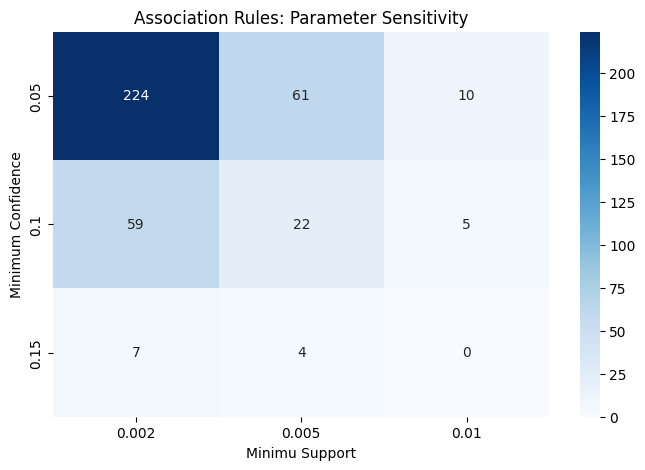

In [86]:
# Create Heatmap
heatmap_data = results_df.pivot(index="Confidence", columns="Support", values="Number of Rules")
plt.figure(figsize=(8,5))

sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")
plt.title("Association Rules: Parameter Sensitivity")
plt.xlabel("Minimu Support")
plt.ylabel("Minimum Confidence")
plt.show()

Section 1(d): Interpretation

1.How does increasing minimum support or confidence affect the number of rules?

Increasing minimum support or confidence decreases the number of association rules because fewer rules meet the higher thresholds. For example, at confidence 0.05, increasing support from 0.002 to 0.01 reduces the number of rules from 224 to 10.

2.Can a rule have high confidence but low lift? Explain

Yes, a rule can have high confidence but low lift. This happens when the consequent item is already frequently purchased. High confidence does not necessarily mean a strong association. A lift close to 1 indicates little or no association between the items.

In [87]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [88]:
import zipfile
# Image Dataset
zip_path = "/content/drive/MyDrive/Programming Assignment/archive.zip"

with zipfile.ZipFile(zip_path, "r") as z: print("Total files:", len(z.namelist()))
print("First 15 files:")
print(z.namelist()[:15])



Total files: 400
First 15 files:
['Dataset/Bus/Image_1.jpg', 'Dataset/Bus/Image_10.jpg', 'Dataset/Bus/Image_100.jpg', 'Dataset/Bus/Image_11.jpg', 'Dataset/Bus/Image_12.jpg', 'Dataset/Bus/Image_13.jpg', 'Dataset/Bus/Image_14.jpg', 'Dataset/Bus/Image_15.jpg', 'Dataset/Bus/Image_16.jpg', 'Dataset/Bus/Image_17.jpg', 'Dataset/Bus/Image_18.jpg', 'Dataset/Bus/Image_19.jpg', 'Dataset/Bus/Image_2.jpg', 'Dataset/Bus/Image_20.jpg', 'Dataset/Bus/Image_21.jpg']


In [89]:
# Check image categories
with zipfile.ZipFile(zip_path, "r") as z:
  folders = sorted(set(name.split("/")[1] for name in z.namelist()
  if name.startswith("Dataset/")
  and len(name.split("/")) > 2))

print("Image categories:", folders)
print("Number of Categories:", len(folders))

Image categories: ['Bus', 'Car', 'Truck', 'motorcycle']
Number of Categories: 4


Section 2(a): Prepare images for CNN

In [90]:
# Import libraries
import os
import tensorflow as tf

# Extract images
with zipfile.ZipFile(zip_path, "r") as z:
  z.extractall("/content/images")

# Dataset location
data_path = "/content/images/Dataset"

# Load and resize images
dataset = tf.keras.utils.image_dataset_from_directory(data_path, image_size=(128, 128), batch_size=32, label_mode="int", seed=42)

# Display categories
print("Classes:", dataset.class_names)

# Normalize images
normalization = tf.keras.layers.Rescaling(1./255)
dataset = dataset.map(lambda x, y: (normalization(x), y))

print("Images loaded successfully!")

Found 400 files belonging to 4 classes.
Classes: ['Bus', 'Car', 'Truck', 'motorcycle']
Images loaded successfully!


In [91]:
# Split images into traning, validation and testing
# Convert dataset into arrays
from sklearn.model_selection import train_test_split

x = []
y = []

for images, labels in dataset:
  x.extend(images.numpy())
  y.extend(labels.numpy())

x = np.array(x)
y = np.array(y)

# 70% training and 30% remaining
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.30, random_state=42, stratify=y)

# Split reamining data equally
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Training:", len(x_train))
print("Validation:", len(x_val))
print("Testing:", len(x_test))


Training: 280
Validation: 60
Testing: 60


**Baseline CNN**

In [92]:
from tensorflow.keras import layers, models

model = models.Sequential([layers.Input(shape=(128, 128, 3)),
                           layers.Conv2D(8, (3,3), activation='relu'),
                           layers.MaxPooling2D(2,2),

                           layers.Conv2D(8, (3,3), activation='relu'),
                           layers.MaxPooling2D(2,2),

                           layers.Flatten(),
                           layers.Dense(16, activation='relu'),
                           layers.Dense(4, activation='softmax')])

# Compile CNN
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=["accuracy"])

# Display model
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 126, 126, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 63, 63, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 61, 61, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 30, 30, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │       115,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 116,092 (453.48 KB)

 Trainable params: 116,092 (453.48 KB)

 Non-trainable params: 0 (0.00 B)

In [93]:
# Train Baseline CNN
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=20, batch_size=32)

# Evaluate model on test images
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 263ms/step - accuracy: 0.3000 - loss: 1.5245 - val_accuracy: 0.3167 - val_loss: 1.3782
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3214 - loss: 1.3650 - val_accuracy: 0.2833 - val_loss: 1.3563
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3500 - loss: 1.3260 - val_accuracy: 0.4167 - val_loss: 1.3260
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3893 - loss: 1.2888 - val_accuracy: 0.3500 - val_loss: 1.3239
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4036 - loss: 1.2495 - val_accuracy: 0.4167 - val_loss: 1.3081
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4143 - loss: 1.2148 - val_accuracy: 0.3333 - val_loss: 1.3374
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4464 - loss: 1.1957 - val_accuracy: 0.3167 - val_loss: 1.3360
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4214 - loss: 1.1457 - val_accuracy: 0.3667 - val_loss: 1.3201

The baseline CNN achieved 57.14% training accuracy, 30% validation accuracy, and 38.33% test accuracy after 20 epochs. The model learned the training images well, but the large difference between training and validation accuracy indicates overfitting. The realtively low test accuracy shows that the model struggles to clasify unseen images across the four categories.

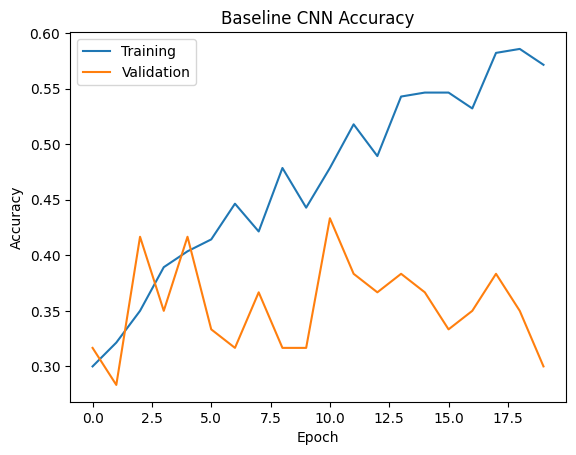

In [94]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Baseline CNN Accuracy')
plt.legend()
plt.show()

Section 2(b): CNN Architecture Experiment

In [95]:
# Model 1: Use 4 filters in the second convolution layer
# Create CNN model
model_1 = models.Sequential([layers.Input(shape=(128, 128, 3)),
                             layers.Conv2D(8, (3,3), activation='relu'),
                             layers.MaxPooling2D(2,2),
                             layers.Conv2D(4, (3,3), activation='relu'),
                             layers.MaxPool2D(2,2),
                             layers.Flatten(),
                             layers.Dense(16, activation='relu'),
                             layers.Dense(4, activation='softmax')])

# Compile the CNN Model
model_1.compile(optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])

# Display model architecture
model_1.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 126, 126, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 63, 63, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 61, 61, 4)      │           292 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 30, 30, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 3600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │        57,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,200 (227.34 KB)

 Trainable params: 58,200 (227.34 KB)

 Non-trainable params: 0 (0.00 B)

In [96]:
# Train Model 1 with filters

# Train the CNN using training and validation images
history_1 = model_1.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=20, batch_size=32)

# Display final training and validation acuracy
print("Training Accuracy:", history_1.history['accuracy'][-1])
print("Validation Accuracy:", history_1.history['val_accuracy'][-1])

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 359ms/step - accuracy: 0.2750 - loss: 1.4057 - val_accuracy: 0.2833 - val_loss: 1.3690
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3429 - loss: 1.3416 - val_accuracy: 0.3667 - val_loss: 1.3387
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5143 - loss: 1.2619 - val_accuracy: 0.4167 - val_loss: 1.3136
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6036 - loss: 1.1715 - val_accuracy: 0.4500 - val_loss: 1.2789
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6643 - loss: 1.0724 - val_accuracy: 0.5000 - val_loss: 1.2694
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7107 - loss: 0.9448 - val_accuracy: 0.4667 - val_loss: 1.2098
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7429 - loss: 0.8221 - val_accuracy: 0.5167 - val_loss: 1.1559
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8036 - loss: 0.6777 - val_accuracy: 0.4500 - val_loss: 1.1690

In [97]:
# Evaluate Model 1 on test on test images
test_loss_1, test_accuracy_1 = model_1.evaluate(x_test, y_test)

print("Model 1 Test Accuracy:", round(test_accuracy_1 * 100, 2), "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5667 - loss: 1.1373
Model 1 Test Accuracy: 56.67 %


Model 1(4 filters) achieved 99.64% training accuracy, 48.33% validation accuracy, and 56.67% test accuracy after 20 epochs. The large difference between training and validation accuracy indicates overfitting. Compared with the Baseline CNN, which achieved 56.67% test accuracy, Model 1 performed better on unseen images.

In [98]:
# Model 2 with 16 filters

# Create second CNN model
model_2 = models.Sequential([layers.Input(shape=(128, 128, 3)),
                             layers.Conv2D(8, (3,3), activation='relu'),
                             layers.MaxPooling2D(2,2),
                             layers.Conv2D(16, (3,3), activation='relu'),
                             layers.MaxPooling2D(2,2),
                             layers.Flatten(),
                             layers.Dense(16, activation='relu'),
                             layers.Dense(4, activation='softmax') ])
# Compile the model
model_2.compile(optimizer='adam', loss= 'sparse_categorical_crossentropy', metrics=['accuracy'])

# Display model architecture
model_2.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 126, 126, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 63, 63, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 61, 61, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 16)             │       230,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 231,876 (905.77 KB)

 Trainable params: 231,876 (905.77 KB)

 Non-trainable params: 0 (0.00 B)

In [99]:
# Train Model 2 for 10 epochs
history_2 = model_2.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=20, batch_size=32)

# Display Final Results
print("Training Accuracy:", history_2.history['accuracy'][-1])
print("Validation Accuracy:", history_2.history['val_accuracy'][-1])



Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 264ms/step - accuracy: 0.2429 - loss: 1.4602 - val_accuracy: 0.3167 - val_loss: 1.3640
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4179 - loss: 1.3307 - val_accuracy: 0.3167 - val_loss: 1.3361
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5214 - loss: 1.2156 - val_accuracy: 0.4667 - val_loss: 1.2426
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6214 - loss: 1.0757 - val_accuracy: 0.4667 - val_loss: 1.2218
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6179 - loss: 0.9422 - val_accuracy: 0.5500 - val_loss: 1.0830
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7536 - loss: 0.7911 - val_accuracy: 0.5667 - val_loss: 1.0279
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7679 - loss: 0.6894 - val_accuracy: 0.5833 - val_loss: 1.0359
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7857 - loss: 0.6075 - val_accuracy: 0.5667 - val_loss: 1.0471

In [100]:
# Evaluate Model 2 on test on test images
test_loss_2, test_accuracy_2 = model_2.evaluate(x_test, y_test)

print("Model 2 Test Accuracy:", round(test_accuracy_1 * 100, 2), "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6333 - loss: 1.4338
Model 2 Test Accuracy: 56.67 %


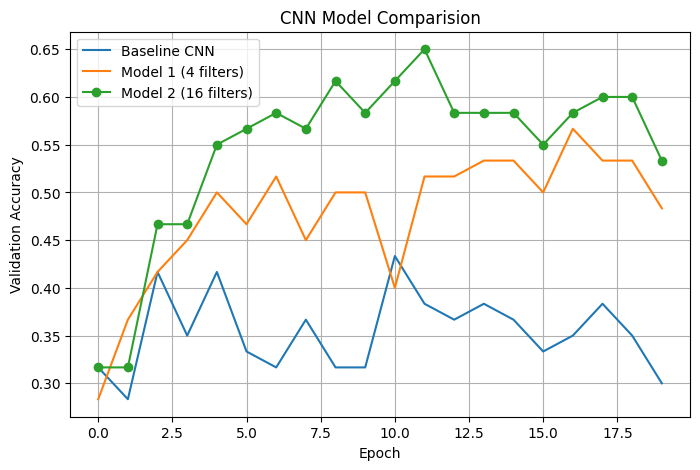

In [101]:
plt.figure(figsize=(8,5))

# Baseline CNN
plt.plot(history.history['val_accuracy'], label='Baseline CNN')

# Model 1: 4 filters
plt.plot(history_1.history['val_accuracy'], label='Model 1 (4 filters)')

# Model 2: 16 filters
plt.plot(history_2.history['val_accuracy'], marker='o', label='Model 2 (16 filters)')

# Chart labels
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('CNN Model Comparision')
plt.legend()
plt.grid(True)
plt.show()

The graph compares the validation accuracy of three CNN models over 20 epochs. Model 2, using 16 filters achieved the highest final validation accuracy of approximately 53.33%. Model 1, using 4 filters showed moderate performance,while the baseline CNN had more fluctuations and lower validation accuracy. Overall, Model 2 performed best in this experiment. However, the difference between training and validation accuracy suggests possible overfitting.

Section 2(c): Learning Curves and Comparision

In [102]:
# Check number of epochs
print("Model 1:", len(history_1.history['accuracy']))
print("Model 2:", len(history_2.history['accuracy']))

Model 1: 20
Model 2: 20


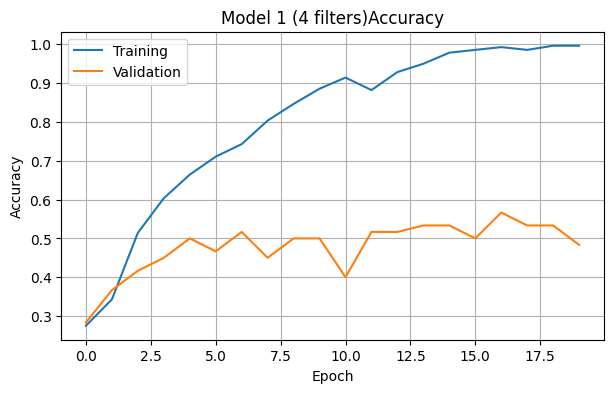

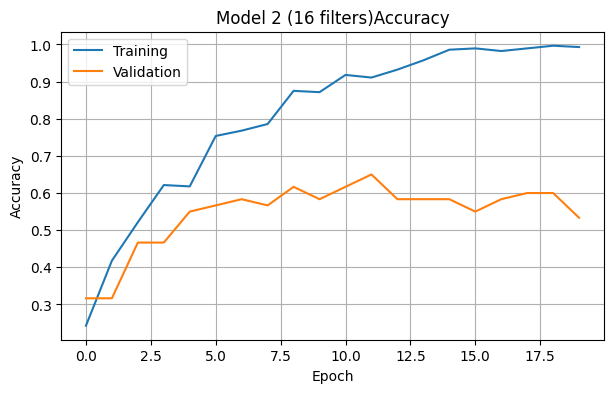

In [103]:
# Compare both models
for name, history in [("Model 1 (4 filters)", history_1), ("Model 2 (16 filters)", history_2)]:
  plt.figure(figsize=(7,4))
  plt.plot(history.history['accuracy'], label='Training')
  plt.plot(history.history['val_accuracy'], label='Validation')

  plt.title(name + "Accuracy")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.grid(True)
  plt.show()

In [104]:
# Create comparision table
comparision = pd.DataFrame({'Model': ['Baseline CNN', 'Model 1', 'Model 2'],
                            'Trainable Parameters': [model.count_params(), model_1.count_params(), model_2.count_params()],
                            'Training Accuracy': [history.history['accuracy'][-1],
                                                  history_1.history['accuracy'][-1],
                                                  history_2.history['accuracy'][-1]]
                                                  ,
                            'Validation Accuracy':[ history.history['val_accuracy'][-1],
                                                   history_1.history['val_accuracy'][-1],
                                                    history_2.history['val_accuracy'][-1]] })
# Display Table
display(comparision.round(4))

,Model,Trainable Parameters,Training Accuracy,Validation Accuracy
0,Baseline CNN,116092,0.9929,0.5333
1,Model 1,58200,0.9964,0.4833
2,Model 2,231876,0.9929,0.5333


Section 2(d): Critical Analysis

1. Which model achieves the highest validation accuracy?

Model 2(16 filters) achieved the highest final validation accuracy, 53.33%, followed by Model 1(48.33%) and the baseline CNN(30%).

2. Does increasing the number of parameters necessarily improve validation accuracy?

No, Although Model 2(231,876 parameters) outperformed the smaller models on final validation accuracy, this experiment alone does not establish that adding parameters always improve generalization. Architecture and training conditions also matter.

3. Based on the learning curves, idetify whether each model shows overfitting, underfitting or neither. Justify your answers.

All three models show evidence of overfitting because their training accuracies are much higher than their validation accuracies.


*   Baseline CNN: 99.29% training accuracy and 53.33% validation accuracy.
*   Model 1(4 filters): 99.64% training accuracy and 48.33% validation accuracy.


*   Model 2(16 filters): 99.29% training accuracy and 53.33% validation accuracy.

This large gap indicates that the models learned the training images well but struggled to generalize to unseen validation images. Increasing the number of filters did not consistently improve validation performance.





Section 3: Multi-Label Text Classification Using BERT

In [105]:
# Import libraries
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

# Import BERT tools
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification


In [106]:
from google.colab import drive
drive.mount('/content/drive')

# Check files in Drive
import os
folder = '/content/drive/MyDrive/Programming Assignment'

print(os.listdir(folder))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['test.json', 'train.json', 'archive.zip', 'validation.json']


In [107]:
# Load tweet datasets
train_df = pd.read_json(folder + '/train.json', lines=True)
test_df = pd.read_json(folder + '/test.json', lines=True)
val_df = pd.read_json(folder + '/validation.json', lines=True)

# Check dataset sizes
print("Training:", train_df.shape)
print("Testing:", test_df.shape)
print("Validation:", val_df.shape)

# Check Column Names
print(train_df.columns.tolist())

# Show first 5 rows
display(train_df.head())

Training: (3000, 13)
Testing: (1500, 13)
Validation: (400, 13)
['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust']


,ID,Tweet,anger,anticipation,disgust,fear,joy,love,optimism,pessimism,sadness,surprise,trust
0,2017-En-10973,So I'm not being shady but one of Jongdae's ex...,False,False,False,False,True,False,False,False,False,False,False
1,2017-En-22236,It's about time I start taking my own advice,False,False,False,False,False,False,True,False,False,False,False
2,2017-En-20530,@jk_rowling never thought an angry oompa loomp...,True,True,True,False,False,False,False,False,True,False,False
3,2017-En-10490,Take public opinion on revenge with Pakistan i...,True,False,True,False,False,False,False,False,False,False,False
4,2017-En-11425,the world drives whoever it has assessed as te...,True,True,False,False,False,False,False,False,False,False,False


In [108]:
# Load BERT tokenizer
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

print("BERT tokenizer loaded successfully!")

BERT tokenizer loaded successfully!


In [109]:
# Convert tweets into BERT tokens
train_tokens = tokenizer(train_df["Tweet"].tolist(), padding=True, max_legth=128, return_tensors='pt')

# Check token dimensions
print("Input IDs:", train_tokens["input_ids"].shape)

Input IDs: torch.Size([3000, 63])


In [110]:
# List of 11 emotion labels
labels = ['anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust']

# Convert True and False labels into 1/0
train_labels = train_df[labels].astype(int)

# Check the label dimensions
print("Labels shape:", train_labels.shape)

# Display first 5 rows
train_labels.head()

Labels shape: (3000, 11)


,anger,anticipation,disgust,fear,joy,love,optimism,pessimism,sadness,surprise,trust
0,0,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,0
2,1,1,1,0,0,0,0,0,1,0,0
3,1,0,1,0,0,0,0,0,0,0,0
4,1,1,0,0,0,0,0,0,0,0,0


In [111]:
# Convert validation labels to 0 and 1
val_labels = val_df[labels].astype(int)

# Check validation labels
print("Validation labels:", val_labels.shape)

# Tokenize validation tweets
val_tokens = tokenizer(val_df["Tweet"].tolist(), padding=True, truncation=True, max_length=128, return_tensors='pt')

print("Validation tokens:", val_tokens["input_ids"].shape)

Validation labels: (400, 11)
Validation tokens: torch.Size([400, 65])


Section 3(a): Fine-tuning BERT


In [112]:
# Create BERT model
from transformers import BertForSequenceClassification

# Load pretrained BERT for binary classification
model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=11, problem_type="multi_label_classification")

print("BERT model created successfully!")

# Check number of output classes
print("Number of classes:", model.config.num_labels)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model created successfully!
Number of classes: 11


In [113]:
# Check GPU avaiability
import torch
from transformers import BertForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Model BERT model to device
model = model.to(device)

print("Using device:", device)

Using device: cuda


In [114]:
# Check actual columns names
print("Training columns:")
print(train_df.columns.tolist())

print("Validation columns:")
print(val_df.columns.tolist())



Training columns:
['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust']
Validation columns:
['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust']


In [115]:
# Select 11 emotion columns
emotion_cols = ["anger", "anticipation", "disgust", "fear", "joy", "love", "optimism", "pessimism", "sadness", "surprise", "trust"]

# Prepare training labels
train_labels = train_df[emotion_cols].values

# Prepare validation labels
val_labels = val_df[emotion_cols].values

# Check shape
print("Training labels:", train_labels.shape)
print("Validation labels:", val_labels.shape)

Training labels: (3000, 11)
Validation labels: (400, 11)


In [116]:
# Prepare datasets for BERT training
from torch.utils.data import TensorDataset, DataLoader

# Convert labels into tensors
train_y = torch.tensor(train_labels, dtype=torch.float32)
val_y = torch.tensor(val_labels, dtype=torch.float32)

# Combine tokens and labels
train_dataset = TensorDataset(train_tokens["input_ids"], train_tokens["attention_mask"], train_y)

val_dataset = TensorDataset(val_tokens["input_ids"], val_tokens["attention_mask"], val_y)

# Create data loaders
train_loaders = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loaders = DataLoader(val_dataset, batch_size=8)

# Check sizes
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 3000
Validation samples: 400


In [117]:
# Set up BERT training
from torch.optim import AdamW

# Optimizer for BERT
optimizer = AdamW(model.parameters(), lr=2e-5)

# Number of training epochs
epochs = 5

# Store losses for plotting
train_losses = []
val_losses = []

print("BERT training setup complete!")

BERT training setup complete!


In [118]:
# Train BERT for 5 epochs
for epoch in range(epochs):
  model.train()
  total_train_loss = 0

  for input_ids, masks, labels in train_loaders:
    input_ids = input_ids.to(device)
    masks = masks.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    output = model(input_ids = input_ids, attention_mask=masks, labels=labels)
    loss = output.loss
    loss.backward()
    optimizer.step()
    total_train_loss += loss.item()

  # Save average training loss
  train_loss = total_train_loss / len(train_loaders)
  train_losses.append(train_loss)

  # Validation
  model.eval()
  total_val_loss = 0

  with torch.no_grad():
    for input_ids, masks, labels in val_loaders:
       input_ids = input_ids.to(device)
       masks = masks.to(device)
       labels = labels.to(device)
       output = model(input_ids=input_ids, attention_mask=masks, labels=labels)
       total_val_loss += output.loss.item()
    # Save average validation loss
    val_loss = (total_val_loss / len(val_loaders))
    val_losses.append(val_loss)
    print(f"Epoch {epoch + 1} /{epochs}")
    print(f"Training Loss: {train_losses[-1]:.4f}")
    print(f"Validation loss:, {val_losses[-1]:.4f}")


Epoch 1 /5
Training Loss: 0.4265
Validation loss:, 0.3393
Epoch 2 /5
Training Loss: 0.3124
Validation loss:, 0.3196
Epoch 3 /5
Training Loss: 0.2592
Validation loss:, 0.3196
Epoch 4 /5
Training Loss: 0.2185
Validation loss:, 0.3203
Epoch 5 /5
Training Loss: 0.1843
Validation loss:, 0.3421


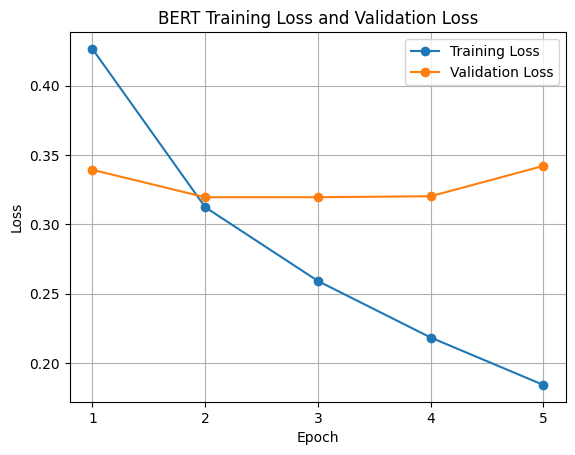

In [119]:
# Plot BERT training loss
import matplotlib.pyplot as plt

# Use the latest 5 epoch losses
train_5 = train_losses[-5:]
val_5 = val_losses[-5:]

plt.plot(range(1, 6), train_5, marker="o", label="Training Loss")
plt.plot(range(1, 6), val_5, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT Training Loss and Validation Loss")
plt.xticks(range(1,6))
plt.legend()
plt.grid(True)
plt.show()

The BERT model was trained for five epochs. Training loss decreased from 0.4265 to 0.1843, while validation loss initially decreased and then increased after Epoach 3. The lowest validation loss was 0.3196 at Epoach 3. This suggests that the model started overfitting after Epoach 3.

Section 3(b): Exact-match accuracy

In [120]:
# Prepare Test Data
# Select the emotion columns
emotion_cols = ["anger", "anticipation", "disgust", "fear", "joy", "love", "optimism", "pessimism", "sadness", "surprise", "trust"]

# Get the true test labels
test_labels = test_df[emotion_cols].values

# Tokenize the test text
test_tokens = tokenizer(test_df["Tweet"].astype(str).tolist(), padding=True, truncation=True, max_length=128, return_tensors="pt")

print("Test tokens created successfully!")
print("Test labels shape:", test_labels.shape)

Test tokens created successfully!
Test labels shape: (1500, 11)


In [121]:
# Combine test tokens and labels
test_dataset = TensorDataset(test_tokens["input_ids"],
                             test_tokens["attention_mask"],
                             torch.tensor(test_labels, dtype=torch.float32))
# Create test loader
test_loader = DataLoader(test_dataset, batch_size=8)
print("Test samples:", len(test_dataset))

Test samples: 1500


In [122]:
# Exact-match accuracy
model.eval()

correct = 0
total = 0

# Evaluate the model
with torch.no_grad():
  for input_ids, attention_mask, labels in test_loader:
    device = next(model.parameters()).device
    input_ids = input_ids.to(device)
    attention_mask = attention_mask.to(device)
    labels = labels.to(device)
    # Get Predictions
    outputs = model(input_ids=input_ids, attention_mask=attention_mask)

    predictions = (torch.sigmoid(outputs.logits) >= 0.5).int()

    #Count exact matches
    correct += (predictions == labels.int()).all(dim=1).sum().item()
    total += labels.size(0)

# Calculate Accuracy
accuracy = correct / total

print("Exact-match accuracy:", round(accuracy, 4))
print("Exact-match accuracy(%):", round(accuracy * 100, 2))

Exact-match accuracy: 0.2527
Exact-match accuracy(%): 25.27


The BERT model achieved an exact-match accuracy of 25.27% on 1,500 test tweets. Exact-match accuracy requires all 11 emotion labels to be predicted correctly for each tweet. This is strict evaluation metric for multi-label classification.

Section 3(c): At-least-one-label accuracy

In [123]:
# At-least-one-label accuracy
model.eval()
device = next(model.parameters()).device

correct = 0
total = 0

# Evaluate test data
with torch.no_grad():
  for input_ids, attention_mask, labels in test_loader:
    input_ids=input_ids.to(device)
    attention_mask=attention_mask.to(device)
    labels=labels.to(device)
    # Get model predictions
    outputs = model(input_ids=input_ids, attention_mask=attention_mask)

    predictions = (torch.sigmoid(outputs.logits) >= 0.5).int()

    # Check atleast one positive emotion match
    matches = ((predictions == 1) & (labels == 1)).any(dim=1)
    correct += matches.sum().item()
    total += labels.size(0)

# Calculate accuracy
one_label_accuracy = correct / total

print("At-least-one-label accuracy:", round(one_label_accuracy, 4))
print("Accuracy(%):", round(one_label_accuracy * 100, 2))

At-least-one-label accuracy: 0.8693
Accuracy(%): 86.93


The BERT model achieved an at-least-one-label accuracy of 86.93%. This means the model correctly identified at least one true positive emotion in 86.93% of the test tweets. This accuracy is higher than exact-match accuracy because only one positive emotion needs to match.

Section 3(d): Micro-F1 score

In [124]:
# Micro-F1 Score
from sklearn.metrics import f1_score

model.eval()
device = next(model.parameters()).device

all_predictions = []
all_labels = []

# Evaluate test data
with torch.no_grad():
  for input_ids, attention_mask, labels in test_loader:
    input_ids=input_ids.to(device)
    attention_mask=attention_mask.to(device)

    # Get model predictions
    outputs = model(input_ids=input_ids, attention_mask=attention_mask)

    # Conver Predictions to 0 or 1
    predictions = (torch.sigmoid(outputs.logits) >= 0.5).int()

    # Store Predictions
    all_predictions.extend(predictions.cpu().numpy())
    all_labels.extend(labels.numpy())

# Calculate Micro-F1 Score
micro_f1 = f1_score(all_labels, all_predictions, average="micro", zero_division=0)

print("Micro-F1 Score:", round(micro_f1, 4))

Micro-F1 Score: 0.6814


The BERT model achieved a Micro-F1 score of 0.6814(68.14%) on the test set. Micro-F1 combines precision and recall across all emotion labels. This metric evaluates labels while accounting for incorrect and missed predictions.

 **Section 3** **(e): Comparision and Interpretation**

 The BERT model achieved an exact-match accuracy of 25.27%, an at-least-one-label accuracy of 86.93%, and a Micro-F1 score of 68.14%.

 The results differ because exact-match accuracy requires all 11 emotion labels to be correct, making it the strict test metric. At-least-one-label accuracy is more lenient because only one correctly predicted positive emotion is required. Micro-F1 balances precision and recall across all emotion labels.

 Micro-F1 is the most informative overall metric for this multi-label classification problem because it considers both false positives and false negatives. Exact-match accuracy is also useful for measuring completely correct predictions, while at-least-one-label accuracy measures partial success but can hide other prediction errors.

